# Module 3: Guest Demographics & Booking Channel Analytics
**Institution:** Invertis University, Bareilly (Faculty of Computer Applications)  
**Project:** ITC Hotels: Revenue & Business Performance Analysis (BCA Final Year Capstone)  
**Project Team:** Jatin Sagar (BC2023727), Atul Kumar (BC2023590), Darshika Rathore (BC2023687), Muskan Saxena (BC2023061)  
**Project Guide:** Ms. Megha Saxena, Assistant Professor  
**Database:** MySQL 8.0 / SQLite 3NF Database (`itc_hotel_analytics.db`)

---
## 1. Executive Summary & Business Context
Understanding guest personas and booking origin channels is vital for customer acquisition cost (CAC) reduction and Club ITC loyalty retention.

This notebook assesses customer origin geographies, channel dependencies (Direct vs OTA vs Corporate), and loyalty tier engagement.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (12, 6)

# Load via SQL from itc_hotel_analytics.db
db_path = '../ITC-Final-Dashboards/itc_hotel_analytics.db'
if os.path.exists(db_path):
    conn = sqlite3.connect(db_path)
    sql_query = """
    SELECT 
        g.booking_id,
        r.hotel_name,
        r.arrival_date,
        r.arrival_year,
        r.arrival_month,
        r.is_canceled,
        g.country_code AS guest_origin_country,
        g.geographic_region,
        g.guest_profile,
        g.adults,
        g.children,
        g.babies,
        g.total_guests,
        g.customer_type,
        g.loyalty_tier AS loyalty_program_tier,
        g.is_repeated_guest,
        g.previous_cancellations,
        g.previous_bookings_not_canceled,
        r.channel AS channel_clean,
        r.market_segment AS market_segment_clean,
        r.lead_time,
        g.special_requests AS total_of_special_requests
    FROM guests g
    JOIN reservations r ON g.booking_id = r.booking_id
    """
    df_demo = pd.read_sql_query(sql_query, conn)
    conn.close()
    print(f"✓ Successfully loaded {len(df_demo):,} records via SQL query")
else:
    df_demo = pd.read_csv('itc_guest_demographics_channels.csv')
    print(f"✓ Loaded {len(df_demo):,} records from CSV")

df_demo.head()

✓ Successfully loaded 87,396 records via SQL query


,booking_id,hotel_name,arrival_date,arrival_year,arrival_month,is_canceled,guest_origin_country,geographic_region,guest_profile,adults,...,total_guests,customer_type,loyalty_program_tier,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,channel_clean,market_segment_clean,lead_time,total_of_special_requests
0,ITC-2015-000001,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,0,PRT,Europe,Business/Solo,2,...,2,Transient,Standard Guest,0,0,0,ITC Direct (Website/Walk-in),Direct,342,0
1,ITC-2015-000002,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,0,PRT,Europe,Business/Solo,2,...,2,Transient,Standard Guest,0,0,0,ITC Direct (Website/Walk-in),Direct,737,0
2,ITC-2015-000003,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,0,GBR,Europe,Business/Solo,1,...,1,Transient,Standard Guest,0,0,0,ITC Direct (Website/Walk-in),Direct,7,0
3,ITC-2015-000004,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,0,GBR,Europe,Business/Solo,1,...,1,Transient,Standard Guest,0,0,0,Corporate Account,Corporate,13,0
4,ITC-2015-000005,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,0,GBR,Europe,Business/Solo,2,...,2,Transient,Standard Guest,0,0,0,Travel Agent / OTA,Online TA,14,1


## 2. Guest Profile & Persona Segmentation

,guest_profile,stays,repeat_guests,avg_lead_time,special_reqs
0,Business/Solo,53306,2877,68.552208,37266
1,Family,9286,129,79.552337,10332
2,Group/MICE,448,142,41.741071,278
3,Family with Kids,331,6,92.489426,306


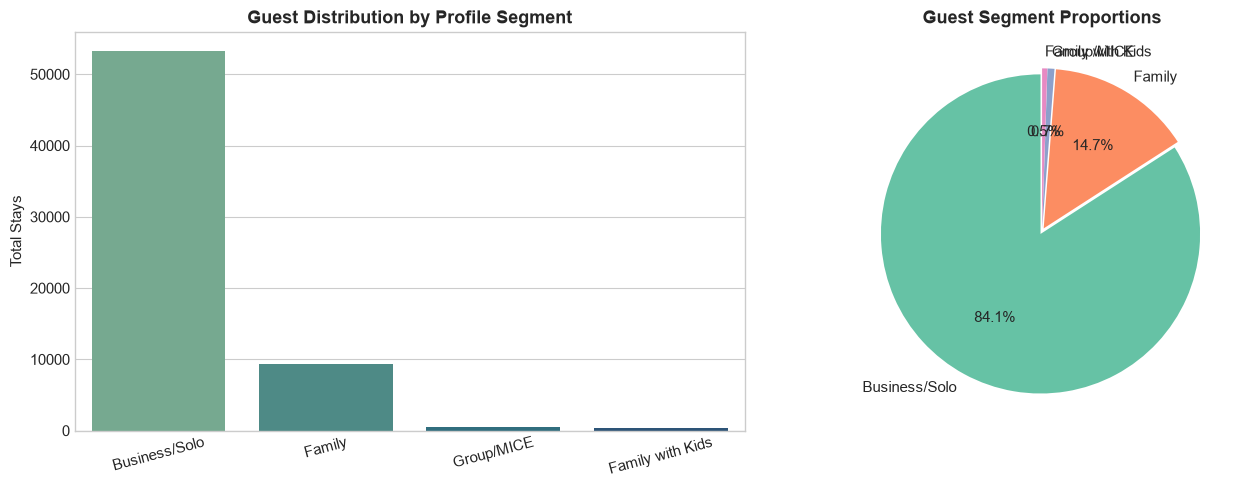

In [2]:
persona_summary = df_demo[df_demo['is_canceled'] == 0].groupby('guest_profile').agg(
    stays=('booking_id', 'count'),
    repeat_guests=('is_repeated_guest', 'sum'),
    avg_lead_time=('lead_time', 'mean'),
    special_reqs=('total_of_special_requests', 'sum')
).sort_values(by='stays', ascending=False).reset_index()

display(persona_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=persona_summary, x='guest_profile', y='stays', ax=axes[0], palette='crest')
axes[0].set_title('Guest Distribution by Profile Segment', fontweight='bold')
axes[0].set_ylabel('Total Stays')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=15)

axes[1].pie(persona_summary['stays'], labels=persona_summary['guest_profile'], 
            autopct='%1.1f%%', startangle=90, colors=sns.color_palette('Set2', len(persona_summary)),
            explode=[0.02]*len(persona_summary))
axes[1].set_title('Guest Segment Proportions', fontweight='bold')

plt.tight_layout()
plt.show()

## 3. Booking Channel Dependency & OTA Commission Risk

,channel_clean,total_bookings,confirmed_stays,cancellations,cancellation_rate,avg_lead_time
0,Travel Agent / OTA,69141,47729,21412,30.968600,88.638478
1,ITC Direct (Website/Walk-in),12988,11063,1925,14.821374,52.362796
2,Corporate Account,5081,4433,648,12.753395,33.416257
3,Global Distribution System,181,145,36,19.889503,20.121547
4,Other,5,1,4,80.000000,23.000000


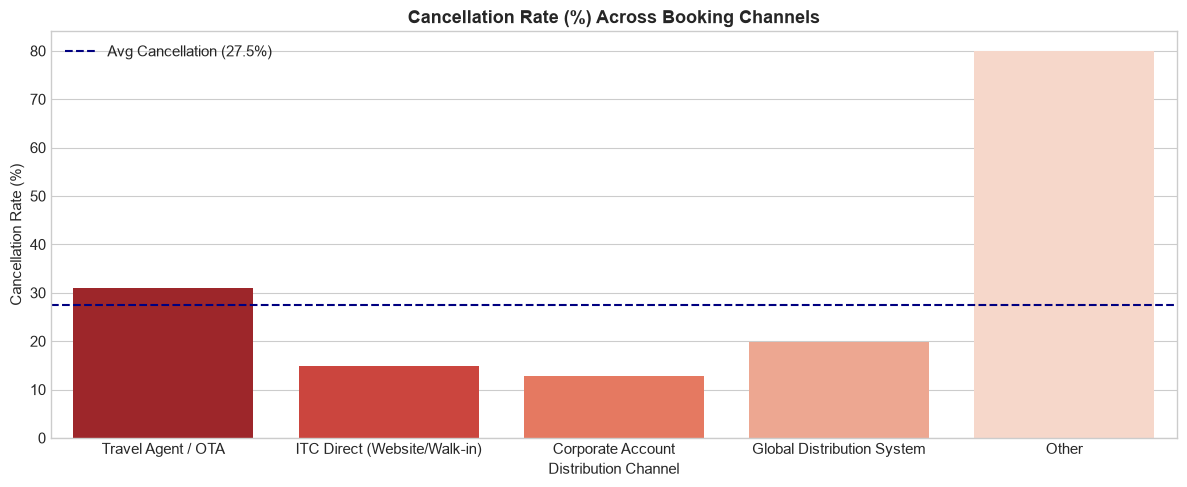

In [3]:
channel_summary = df_demo.groupby('channel_clean').agg(
    total_bookings=('booking_id', 'count'),
    confirmed_stays=('is_canceled', lambda x: (x == 0).sum()),
    cancellations=('is_canceled', lambda x: (x == 1).sum()),
    cancellation_rate=('is_canceled', lambda x: x.mean() * 100),
    avg_lead_time=('lead_time', 'mean')
).sort_values(by='total_bookings', ascending=False).reset_index()

display(channel_summary)

plt.figure(figsize=(12, 5))
sns.barplot(data=channel_summary, x='channel_clean', y='cancellation_rate', palette='Reds_r')
plt.title('Cancellation Rate (%) Across Booking Channels', fontweight='bold', fontsize=13)
plt.ylabel('Cancellation Rate (%)')
plt.xlabel('Distribution Channel')
plt.axhline(df_demo['is_canceled'].mean()*100, color='navy', linestyle='--', label=f'Avg Cancellation ({df_demo["is_canceled"].mean()*100:.1f}%)')
plt.legend()
plt.tight_layout()
plt.show()